In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

professions = pd.read_csv("counts.csv")
professions.head()

,profession,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius,Capricorn,Aquarius,Pisces
0,AV actress,14,7,12,10,13,15,7,11,6,11,13,16
1,Africanist,14,18,14,14,12,18,17,7,10,15,8,11
2,American football coach,153,148,147,155,155,166,193,161,168,152,165,186
3,American football player,2361,2282,2340,2472,2462,2570,2473,2389,2355,2446,2503,2583
4,Anglican priest,237,244,241,233,223,241,242,212,236,252,223,218


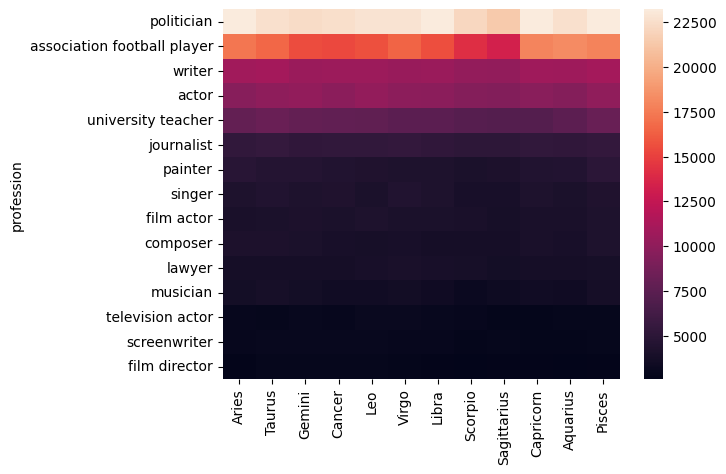

In [2]:
#grab the top 15 professions
professions['total'] = professions.drop('profession', axis=1).sum(axis=1)
prof_top_15 = professions.nlargest(15, 'total')
prof_top_15 = prof_top_15.drop('total', axis=1)
prof_heatmap = prof_top_15.set_index('profession')

sns.heatmap(prof_heatmap)
plt.show()


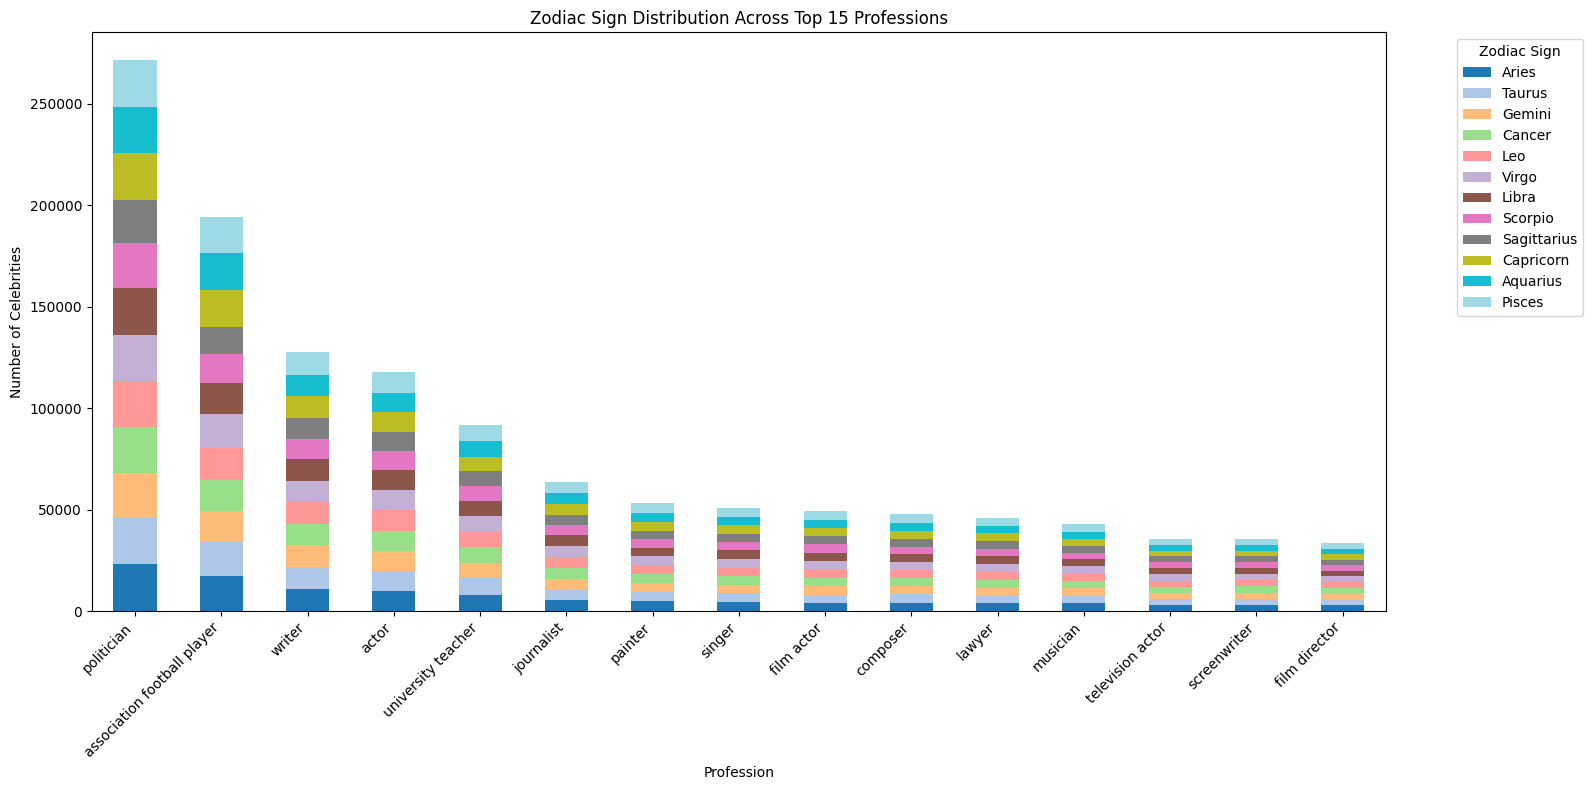

In [ ]:
prof_heatmap.plot(kind='bar', stacked=True, figsize=(16, 8), colormap='tab20')

plt.title('Zodiac Sign Distribution Across Top 15 Professions')
plt.xlabel('Profession')
plt.ylabel('Number of Celebrities')
plt.legend(title='Zodiac Sign', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

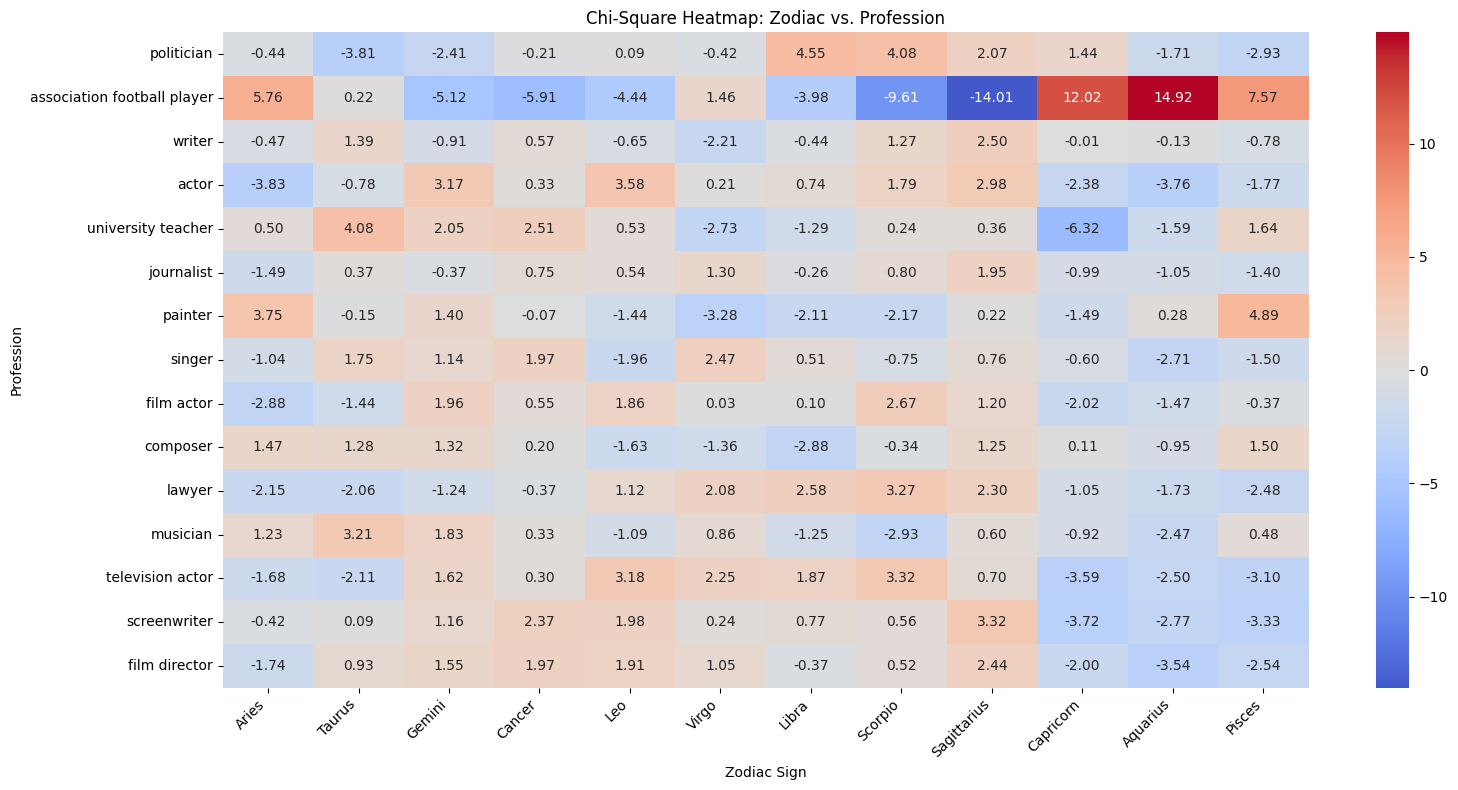

In [ ]:
from scipy.stats import chi2_contingency
import numpy as np

chi2, p_value, dof, expected = chi2_contingency(prof_heatmap)

#calculate residuals
#(observed - expected) / square_root(expected)
residuals = (prof_heatmap - expected) / np.sqrt(expected)

plt.figure(figsize=(16, 8))
sns.heatmap(residuals, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Chi-Square Heatmap: Zodiac vs. Profession')
plt.xlabel('Zodiac Sign')
plt.ylabel('Profession')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()